In [1]:
import rawpy
import sys 
import os
from pathlib import Path
import importlib
import matplotlib.pyplot as plt
from PIL import Image, ExifTags
import numpy as np
import cv2
import imageio
import tifffile
import seaborn as sns
from pathlib import Path
import colour
# 1. Load the standard chart data
cc24_data = colour.CCS_COLOURCHECKERS["ColorChecker24 - After November 2014"]
# 2. Convert the reference data from xyY color space to XYZ tristimulus values (t)
xyY_values = np.array(list(cc24_data.data.values()))

# 3. Convert the xyY array directly into CIE XYZ tristimulus values (t)
t_XYZ = colour.xyY_to_XYZ(list(xyY_values))

helperFolder = Path("helper")
if str(helperFolder.resolve()) not in sys.path:
    sys.path.insert(0, str(helperFolder.resolve()))

import utils
import psu_imaging as psu
importlib.reload(utils)
importlib.reload(psu)


print(cv2.__version__)

5.0.0


# Deliverable 1: Classic Image Pipeline

In [8]:
measurement1ImageFolder = Path("images")
measurement1ChartPaths = [
    measurement1ImageFolder / f"IMG_{imageNumber}.DNG"
    for imageNumber in ("0290", "0291", "0292")
]
measurement1FlatFieldPath = measurement1ImageFolder / "IMG_0293.DNG"
for imagePath in [*measurement1ChartPaths, measurement1FlatFieldPath]:
    if not imagePath.is_file():
        raise FileNotFoundError(f"Missing color-chart image: {imagePath.resolve()}")


In [10]:
# Black level subtraction on one RAW Bayer mosaic
importlib.reload(utils)

imagePath = measurement1ChartPaths[0]
with rawpy.imread(str(imagePath)) as raw:
    if raw.raw_pattern is None or raw.raw_pattern.shape != (2, 2):
        raise ValueError("Black level correction requires a 2 x 2 Bayer pattern")
    bayerMosaic = raw.raw_image_visible.astype(np.float64)
    visiblePattern = raw.raw_colors_visible[:2, :2].copy()
    visibleColors = np.array([chr(raw.color_desc[index]) for index in visiblePattern.flat]).reshape(2, 2)
    visibleMargins = (raw.sizes.top_margin, raw.sizes.left_margin)
    siteBlackLevels = np.asarray(raw.black_level_per_channel, dtype=np.float64)[visiblePattern]
    whiteLevel = raw.white_level

blackCorrectedMosaic = utils.subtract_black_level(bayerMosaic, siteBlackLevels)
saturationResult = utils.normalize_saturation(blackCorrectedMosaic, siteBlackLevels, whiteLevel)
normalizedMosaic = saturationResult["corrected"]

print(f"Image: {imagePath.name}; mosaic shape: {bayerMosaic.shape}")
print(f"Black levels by visible Bayer site (DN):\n{siteBlackLevels}")
print(f"Original range (DN): {bayerMosaic.min():.0f} to {bayerMosaic.max():.0f}")
print(f"Black-subtracted range (DN): {blackCorrectedMosaic.min():.0f} to "
      f"{blackCorrectedMosaic.max():.0f}")
print(f"White level (DN): {whiteLevel}; saturated samples: "
      f"{np.count_nonzero(saturationResult['saturationMask'])}")

Image: IMG_0290.DNG; mosaic shape: (3024, 4032)
Black levels by visible Bayer site (DN):
[[ 528.  528.]
 [ 528.  528.]]
Original range (DN): 488 to 838
Black-subtracted range (DN): -40 to 310
White level (DN): 4095; saturated samples: 0


Defect correction will follow once a dark frame matched to this capture is available. 
Use `utils.find_defective_pixels` on the dark mosaic and 
`utils.correct_defective_pixels` on `normalizedMosaic`; verify candidate pixels 
using additional matched dark frames.

## Lens shading correction

The Project 1 flat is provisional: uneven illumination can be mistaken for lens shading. 
Compare independent uniformly illuminated flats before trusting this correction.

In [11]:
importlib.reload(utils)

project1FlatPath = Path("..") / "01_project" / "images" / "IMG_0297.DNG"
sceneLens = utils.lens_id(imagePath)
flatLens = utils.lens_id(project1FlatPath)
if (sceneLens["lensModel"] == "unknown" or
        any(sceneLens[key] != flatLens[key] for key in ("lensModel", "focalLengthMm", "imageSize"))):
    raise ValueError("Scene and Project 1 flat must use the same camera lens and image size")

with rawpy.imread(str(project1FlatPath)) as rawFlat:
    if rawFlat.raw_pattern is None or rawFlat.raw_pattern.shape != (2, 2):
        raise ValueError("Project 1 flat must have a 2 x 2 Bayer pattern")
    flatMosaic = rawFlat.raw_image_visible.copy()
    flatPattern = rawFlat.raw_colors_visible[:2, :2].copy()
    flatColors = np.array([chr(rawFlat.color_desc[index]) for index in flatPattern.flat]).reshape(2, 2)
    flatMargins = (rawFlat.sizes.top_margin, rawFlat.sizes.left_margin)
    flatBlackLevels = np.asarray(rawFlat.black_level_per_channel, dtype=np.float64)[flatPattern]
    flatWhiteLevel = rawFlat.white_level

if (flatMosaic.shape != bayerMosaic.shape or flatMargins != visibleMargins or
        not np.array_equal(flatColors, visibleColors)):
    raise ValueError("Scene and flat must have the same visible crop and Bayer phase")
if np.any(flatMosaic >= flatWhiteLevel):
    raise ValueError("Project 1 flat contains saturated samples")

flatBlackCorrected = utils.subtract_black_level(flatMosaic, flatBlackLevels)
shadingMap = utils.build_bayer_shading_map(flatBlackCorrected, roiSize=64, sigma=32)
shadingCorrectedMosaic = utils.correct_bayer_lens_shading(
    normalizedMosaic, shadingMap["normalizedFlat"],
)
print(f"Flat: {project1FlatPath.name}; Bayer sites:\n{visibleColors}")
print(f"Flat center means (black-subtracted DN):\n{shadingMap['centerMeans']}")
print(f"Normalized response range: {shadingMap['normalizedFlat'].min():.3f} to "
      f"{shadingMap['normalizedFlat'].max():.3f}")
print("Provisional: verify flat illumination and compare independent captures.")

Flat: IMG_0297.DNG; Bayer sites:
[['B' 'G']
 ['G' 'R']]
Flat center means (black-subtracted DN):
[[ 652.21495832  917.87580675]
 [ 916.28836066  390.65857605]]
Normalized response range: 0.154 to 1.101
Provisional: verify flat illumination and compare independent captures.


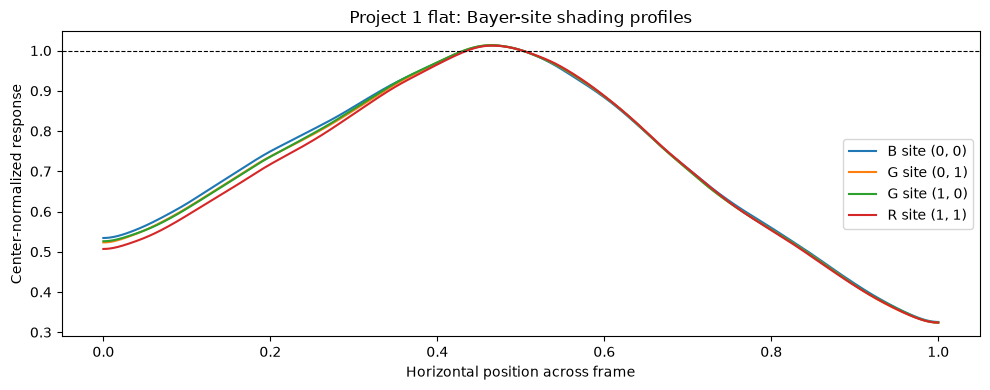

In [12]:
figure, axis = plt.subplots(figsize=(10, 4))
for row, column in np.ndindex(2, 2):
    responsePlane = shadingMap["normalizedFlat"][row::2, column::2]
    centerRow = responsePlane.shape[0] // 2
    profile = responsePlane[centerRow - 8:centerRow + 8].mean(axis=0)
    axis.plot(np.linspace(0, 1, profile.size), profile,
              label=f"{visibleColors[row, column]} site ({row}, {column})")
axis.axhline(1, color="black", linestyle="--", linewidth=0.8)
axis.set(xlabel="Horizontal position across frame", ylabel="Center-normalized response",
         title="Project 1 flat: Bayer-site shading profiles")
axis.legend()
figure.tight_layout()
plt.show()

Compare the correction against a second flat using 64-by-64 site-plane regions. 
This is a diagnostic, not independent ground truth: the second flat may also 
have uneven illumination.

In [13]:
importlib.reload(utils)

checkLens = utils.lens_id(measurement1FlatFieldPath)
if any(sceneLens[key] != checkLens[key] for key in ("lensModel", "focalLengthMm", "imageSize")):
    raise ValueError("Validation flat must use the same camera lens and image size")
with rawpy.imread(str(measurement1FlatFieldPath)) as rawCheck:
    checkFlat = rawCheck.raw_image_visible.copy()
    checkPattern = rawCheck.raw_colors_visible[:2, :2].copy()
    checkColors = np.array([chr(rawCheck.color_desc[index]) for index in checkPattern.flat]).reshape(2, 2)
    checkMargins = (rawCheck.sizes.top_margin, rawCheck.sizes.left_margin)
    checkBlackLevels = np.asarray(rawCheck.black_level_per_channel, dtype=np.float64)[checkPattern]
    checkWhiteLevel = rawCheck.white_level
if (checkFlat.shape != bayerMosaic.shape or checkMargins != visibleMargins or
        not np.array_equal(checkColors, visibleColors)):
    raise ValueError("Validation flat must have the same visible crop and Bayer phase")
if np.any(checkFlat >= checkWhiteLevel):
    raise ValueError("Validation flat contains saturated samples")

checkBlackCorrected = utils.subtract_black_level(checkFlat, checkBlackLevels)
checkShadingCorrected = utils.correct_bayer_lens_shading(
    checkBlackCorrected, shadingMap["normalizedFlat"],
)
for row, column in np.ndindex(2, 2):
    print(f"{visibleColors[row, column]} site ({row}, {column}):")
    for label, image in (("before", checkBlackCorrected), ("after", checkShadingCorrected)):
        plane = image[row::2, column::2]
        height, width = plane.shape
        center = plane[height//2 - 32:height//2 + 32, width//2 - 32:width//2 + 32].mean()
        if center <= 0:
            raise ValueError("Validation flat center must be positive")
        corners = [plane[y:y + 64, x:x + 64].mean() / center for y, x in
                   ((0, 0), (0, width - 64), (height - 64, 0), (height - 64, width - 64))]
        print(f"  {label} corner/center ratios: {np.round(corners, 3)}")

B site (0, 0):
  before corner/center ratios: [ 0.348  0.279  0.373  0.288]
  after corner/center ratios: [ 0.756  0.73   1.06   1.793]
G site (0, 1):
  before corner/center ratios: [ 0.333  0.267  0.36   0.282]
  after corner/center ratios: [ 0.73   0.712  1.046  1.724]
G site (1, 0):
  before corner/center ratios: [ 0.333  0.267  0.36   0.283]
  after corner/center ratios: [ 0.729  0.711  1.045  1.727]
R site (1, 1):
  before corner/center ratios: [ 0.32   0.26   0.351  0.284]
  after corner/center ratios: [ 0.729  0.712  1.051  1.711]


# Deliverable 2: Learned Stage

In [14]:
importlib.reload(utils)

pipeline = utils.classicImagePipeline(measurement1ChartPaths[0])
intrinsics = pipeline.get_intrinsics()

print(intrinsics["visibleColors"])
print(intrinsics["siteBlackLevels"])

[['B' 'G']
 ['G' 'R']]
[[ 528.  528.]
 [ 528.  528.]]


In [16]:
pipeline.subtract_black_level()
pipeline.normalize_saturation()

# Once a suitable dark and measured threshold are available:
# pipeline.correct_defective_pixels(
#     darkPath, defectThresholdDN=defectThresholdDN
# )

pipeline.correct_lens_shading(
    Path("../01_project/images/IMG_0297.DNG"),
    roiSize=64,
    sigma=32,
)

pipeline.white_balance()          # Camera metadata gains
pipeline.demosaic(method="mhc")   # Or "bilinear"
pipeline.denoise(method="bilateral", sigmaColor=0.05, sigmaSpace=2)

linearCameraRgb = pipeline.image.copy()

ValueError: Stage requires ('raw_dn',); current domain is linear_camera_rgb

In [17]:
pipeline.color_correct(
    measuredMatrix,
    referenceIlluminant=referenceIlluminant,
)
pipeline.tone_curve(exposure=0.0)
pipeline.sharpen(amount=0.5, sigma=1.0)

plt.imshow(pipeline.image)
plt.axis("off")
plt.show()

pipeline.image           # Current processed array
pipeline.domain          # Current representation/units
pipeline.history         # Stages and parameters applied
pipeline.saturationMask  # Original sensor saturation mask

pipeline.reset()         # Restore original RAW and clear processing history

NameError: name 'measuredMatrix' is not defined

In [ ]:
pipeline.reset().subtract_black_level().normalize_saturation()

# Deliverable 3: Deployment